# Rede de Administradores Compartilhados entre S.A. Abertas Brasileiras
**OPT108 – Grupo 7: Rede Societária e Concentração de Mercado (CNPJ)**

Pergunta de pesquisa (enunciado): *a densidade e o grau de intermediação da rede societária aumentaram nos últimos anos, sinalizando maior interlocking directorates e concentração corporativa?*

Pipeline:
1. `01_preparar_dados.py` baixa e filtra os dados abertos do CNPJ (snapshot 2024-09).
2. Este notebook monta o grafo bipartido pessoa ↔ empresa, projeta em empresa–empresa e calcula as métricas.

**Rodando no Google Colab:** a célula abaixo clona o repositório e gera a pasta `data/` com o `01_preparar_dados.py` (baixa ~4 GB da Receita, leva alguns minutos). Rodando localmente com `data/` pronta, ela não faz nada.

In [1]:
import os
if not os.path.exists('data/socios.csv'):
    if not os.path.exists('01_preparar_dados.py'):
        !git clone -q https://github.com/viictor1/opt108-rede-societaria.git
        %cd opt108-rede-societaria
    !pip -q install adjustText
    !python 01_preparar_dados.py

In [2]:
import pandas as pd, numpy as np, networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
from networkx.algorithms import bipartite
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10})
SEED = 42
import os; os.makedirs('figuras', exist_ok=True); os.makedirs('tabelas', exist_ok=True)

# Estilo comum das figuras
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']  # 8 cores categóricas, ordem fixa
OUTRAS, INK, INK2, GRID, AXIS = '#c9c8c2', '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
                     'axes.titlelocation': 'left', 'text.color': INK})

## 1. Carregamento e limpeza

In [3]:
emp = pd.read_csv('data/empresas.csv', sep=';', dtype=str)
soc = pd.read_csv('data/socios.csv', sep=';', dtype=str)
est = pd.read_csv('data/estabelecimentos.csv', sep=';', dtype=str)

emp['capital_social'] = emp.capital_social.str.replace(',', '.').astype(float)
est = est[['cnpj', 'situacao', 'data_inicio', 'cnae_principal', 'uf']]
emp = emp.merge(est, on='cnpj', how='left')

print('S.A. abertas no cadastro:', len(emp))
print(emp.situacao.map({'01':'nula','02':'ativa','03':'suspensa','04':'inapta','08':'baixada'}).value_counts())

S.A. abertas no cadastro: 3169
situacao
baixada     1629
ativa       1082
inapta       438
suspensa      15
nula           5
Name: count, dtype: int64


In [4]:
# Mantém só empresas ATIVAS (situação 02)
ativas = set(emp.loc[emp.situacao == '02', 'cnpj'])
soc = soc[soc.cnpj.isin(ativas)].copy()

# Tabela de qualificações (Receita Federal) mais comuns no QSA de S.A.
QUAL = {'05':'Administrador','08':'Conselheiro de Administração','10':'Diretor','16':'Presidente',
        '22':'Sócio','28':'Sócio-Gerente','37':'Sócio PJ no exterior','49':'Sócio-Administrador',
        '63':'Cotas em Tesouraria','71':'Conselheiro (exterior)','72':'Diretor (exterior)'}
soc['qualificacao_nome'] = soc.qualificacao.map(QUAL).fillna('Outra')

# Identificador da pessoa: o CPF vem mascarado (***123456**), então usamos nome + CPF mascarado.
# Para sócio PJ o documento é o CNPJ completo.
soc['pessoa'] = soc.tipo_socio + '|' + soc.nome_socio.str.strip().str.upper() + '|' + soc.doc_socio.fillna('')
soc['data_entrada'] = pd.to_datetime(soc.data_entrada, format='%Y%m%d', errors='coerce')

# Remove duplicatas (mesma pessoa listada 2x na mesma empresa) e vínculos sem nome
antes = len(soc)
soc = soc.dropna(subset=['nome_socio']).sort_values('data_entrada').drop_duplicates(['cnpj', 'pessoa'])
print(f'Vínculos: {antes} -> {len(soc)} após limpeza')
print('Empresas ativas com QSA:', soc.cnpj.nunique(), '| Pessoas distintas:', soc.pessoa.nunique())
soc.qualificacao_nome.value_counts()

Vínculos: 5443 -> 5443 após limpeza
Empresas ativas com QSA: 1035 | Pessoas distintas: 4513


qualificacao_nome
Diretor                         3139
Conselheiro de Administração    1525
Presidente                       680
Administrador                     84
Cotas em Tesouraria                5
Sócio                              4
Sócio PJ no exterior               3
Sócio-Administrador                1
Sócio-Gerente                      1
Outra                              1
Name: count, dtype: int64

## 2. Grafo bipartido e projeção
**Modelagem.** Vértice = empresa (S.A. aberta ativa). Aresta = as duas empresas têm pelo menos um administrador (diretor, conselheiro ou presidente) em comum.
- **Não direcionado**: dividir um administrador é uma relação simétrica, e o QSA não diz qual empresa indicou a pessoa.
- **Ponderado**: peso = nº de administradores em comum. Dividir 1 conselheiro é diferente de dividir a diretoria inteira (típico de empresas do mesmo grupo, o que importa pra QP3).
- Empresas sem nenhum administrador em comum ficam como **vértices isolados** de propósito, porque fazem parte da população e entram na densidade e na fração de empresas interligadas.

In [5]:
B = nx.Graph()
B.add_nodes_from(soc.cnpj.unique(), bipartite=0)
B.add_nodes_from(soc.pessoa.unique(), bipartite=1)
B.add_edges_from(zip(soc.cnpj, soc.pessoa))

empresas_nos = set(soc.cnpj)
# Projeção unipartida: empresas ligadas se dividem >= 1 administrador; peso = nº de administradores em comum
G0 = bipartite.weighted_projected_graph(B, empresas_nos)
# Reconstrói em ordem fixa: o Louvain depende da ordem dos nós, e conjuntos (set) mudam de ordem a cada execução
G = nx.Graph()
G.add_nodes_from(sorted(G0.nodes))
G.add_edges_from(sorted((min(u, v), max(u, v), d) for u, v, d in G0.edges(data=True)))
nome = emp.set_index('cnpj').razao_social.to_dict()
nx.set_node_attributes(G, nome, 'nome')

# Pessoas que fazem a ponte (estão em 2+ empresas)
boards = soc.groupby('pessoa').cnpj.nunique()
print('Pessoas em 2+ empresas (interlockers):', (boards >= 2).sum(), f'({(boards>=2).mean():.1%})')
print('Empresas com pelo menos 1 interlock:', sum(1 for n in G if G.degree(n) > 0), 'de', G.number_of_nodes())

Pessoas em 2+ empresas (interlockers): 558 (12.4%)
Empresas com pelo menos 1 interlock: 439 de 1035


## 3. Estatísticas descritivas

In [6]:
def resumo(G):
    lcc = G.subgraph(max(nx.connected_components(G), key=len))
    return {
        '|V|': G.number_of_nodes(), '|E|': G.number_of_edges(),
        'densidade': nx.density(G), 'grau médio': 2*G.number_of_edges()/G.number_of_nodes(),
        'isolados': nx.number_of_isolates(G), 'componentes': nx.number_connected_components(G),
        '|V| do maior componente': lcc.number_of_nodes(),
        '% no maior componente': lcc.number_of_nodes()/G.number_of_nodes(),
        'clustering médio': nx.average_clustering(G),
        'transitividade': nx.transitivity(G),
        'dist. média (maior comp.)': nx.average_shortest_path_length(lcc),
        'diâmetro (maior comp.)': nx.diameter(lcc),
    }
desc = pd.Series(resumo(G)).to_frame('valor')
desc.to_csv('tabelas/estatisticas_descritivas.csv'); desc

,valor
|V|,1035.000000
|E|,706.000000
densidade,0.001319
grau médio,1.364251
isolados,596.000000
componentes,689.000000
|V| do maior componente,121.000000
% no maior componente,0.116908
clustering médio,0.208738
transitividade,0.814864


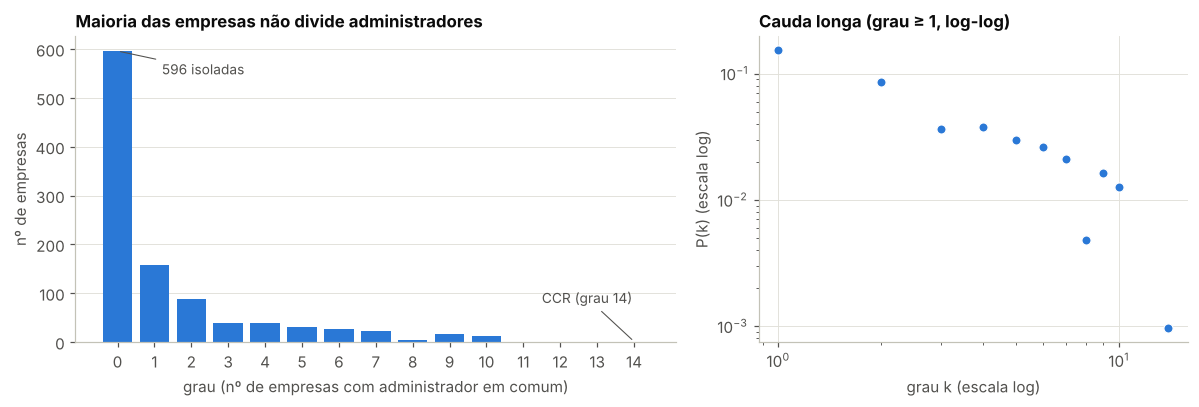

In [7]:
graus = pd.Series(dict(G.degree()))
cont = graus.value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1.4, 1]})
ax[0].bar(cont.index, cont.values, width=0.8, color=CAT[0])
ax[0].set_xticks(range(0, graus.max() + 1))
ax[0].set(xlabel='grau (nº de empresas com administrador em comum)', ylabel='nº de empresas',
          title='Maioria das empresas não divide administradores')
ax[0].grid(axis='x', visible=False)
ax[0].annotate(f'{cont[0]} isoladas', (0, cont[0]), xytext=(1.2, cont[0] * 0.92), fontsize=9, color=INK2,
               arrowprops=dict(arrowstyle='-', color=INK2, lw=0.7))
ax[0].annotate(f'CCR (grau {graus.max()})', (graus.max(), cont[graus.max()]), xytext=(graus.max() - 2.5, 80),
               fontsize=9, color=INK2, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.7))
pk = cont[cont.index > 0] / len(graus)
ax[1].loglog(pk.index, pk.values, 'o', ms=6, color=CAT[0], mec='white', mew=0.8)
ax[1].set(xlabel='grau k (escala log)', ylabel='P(k) (escala log)', title='Cauda longa (grau ≥ 1, log-log)')
plt.tight_layout(); plt.savefig('figuras/distribuicao_graus.png', bbox_inches='tight'); plt.show()

## 4. Centralidades

In [8]:
lcc_nodes = max(nx.connected_components(G), key=len)
L = G.subgraph(sorted(lcc_nodes)).copy()

# Para caminhos, peso maior = ligação mais forte = distância menor
for u, v, d in G.edges(data=True):
    d['dist'] = 1 / d['weight']

cent = pd.DataFrame({
    'grau': dict(G.degree()),
    'grau_ponderado': dict(G.degree(weight='weight')),
    'intermediacao': nx.betweenness_centrality(G, weight='dist', normalized=True),
    'proximidade': nx.closeness_centrality(G, distance='dist'),
    'pagerank': nx.pagerank(G, weight='weight'),
})
cent['autovetor'] = pd.Series(nx.eigenvector_centrality_numpy(L, weight='weight'))
cent['autovetor'] = cent.autovetor.fillna(0)
cent['nome'] = cent.index.map(nome)
cent['cnae'] = cent.index.map(emp.set_index('cnpj').cnae_principal)
cent.sort_values('intermediacao', ascending=False).head(15)

,grau,grau_ponderado,intermediacao,proximidade,pagerank,autovetor,nome,cnae
02846056,14,21,0.004888,0.034391,0.004629,1.400217e-06,CCR S.A.,6462000
61532644,6,12,0.004763,0.034434,0.003131,1.366332e-06,ITAUSA S.A.,6462000
91983056,4,4,0.004737,0.029708,0.001671,9.310482e-03,KEPLER WEBER SA,6462000
03847461,7,18,0.004550,0.026341,0.002580,2.653254e-01,BRADESPAR S.A.,6462000
89086144,4,6,0.003593,0.031854,0.002209,3.465439e-05,RANDON SA IMPLEMENTOS E PARTICIPACOES,2930101
12091809,4,8,0.003492,0.029852,0.002762,4.528991e-07,3R PETROLEUM OLEO E GAS S.A.,0600001
42150391,5,5,0.003367,0.022736,0.001711,5.596221e-10,BRASKEM S.A,2021500
88610126,2,4,0.003363,0.030843,0.001579,3.291112e-04,FRAS-LE SA,2943300
08827501,8,16,0.002973,0.031119,0.003607,1.279028e-07,AEGEA SANEAMENTO E PARTICIPACOES S.A.,6462000
60872504,8,16,0.002897,0.032032,0.004553,2.092434e-07,ITAU UNIBANCO HOLDING S.A.,6431000


In [9]:
top = {}
for m in ['grau', 'intermediacao', 'proximidade', 'pagerank', 'autovetor']:
    top[m] = cent.sort_values(m, ascending=False).head(10).nome.str[:45].tolist()
top = pd.DataFrame(top, index=range(1, 11))
top.to_csv('tabelas/top10_centralidades.csv'); top

,grau,intermediacao,proximidade,pagerank,autovetor
1,CCR S.A.,CCR S.A.,LINHAS DE MACAPA TRANSMISSORA DE ENERGIA S.A.,BANCO BRADESCO S.A.,BANCO BRADESCO S.A.
2,EQUATORIAL S.A.,ITAUSA S.A.,LINHAS DE XINGU TRANSMISSORA DE ENERGIA S.A.,CCR S.A.,BRADESCO LEASING S.A. - ARRENDAMENTO MERCANTI
3,ENERGISA MATO GROSSO - DISTRIBUIDORA DE ENERG,KEPLER WEBER SA,ENERGISA SUL-SUDESTE - DISTRIBUIDORA DE ENERG,ITAU UNIBANCO HOLDING S.A.,NCF PARTICIPACOES S.A.
4,ENERGISA S/A,BRADESPAR S.A.,ITAUSA S.A.,HIDROVIAS DO BRASIL S.A.,BRADESPAR S.A.
5,ENERGISA TRANSMISSAO DE ENERGIA S.A.,RANDON SA IMPLEMENTOS E PARTICIPACOES,CCR S.A.,BRADESCO LEASING S.A. - ARRENDAMENTO MERCANTI,ODONTOPREV S.A.
6,ENERGISA SUL-SUDESTE - DISTRIBUIDORA DE ENERG,3R PETROLEUM OLEO E GAS S.A.,ENERGISA MATO GROSSO DO SUL - DISTRIBUIDORA D,CYRELA BRAZIL REALTY S.A. EMPREENDIMENTOS E P,CIELO S.A - INSTITUICAO DE PAGAMENTO
7,ARTERIS S.A.,BRASKEM S.A,ENERGISA PARAIBA - DISTRIBUIDORA DE ENERGIA S,EQUATORIAL S.A.,SOLVI ESSENCIS AMBIENTAL S.A.
8,ENERGISA MINAS RIO - DISTRIBUIDORA DE ENERGIA,FRAS-LE SA,ENERGISA MATO GROSSO - DISTRIBUIDORA DE ENERG,GERDAU S.A.,EQUATORIAL S.A.
9,ENERGISA MATO GROSSO DO SUL - DISTRIBUIDORA D,AEGEA SANEAMENTO E PARTICIPACOES S.A.,ENERGISA SERGIPE - DISTRIBUIDORA DE ENERGIA S,AEGEA SANEAMENTO E PARTICIPACOES S.A.,COMPANHIA ESTADUAL DE DISTRIBUICAO DE ENERGIA
10,ENERGISA SERGIPE - DISTRIBUIDORA DE ENERGIA S,ITAU UNIBANCO HOLDING S.A.,DEXCO S.A,NCF PARTICIPACOES S.A.,EQUATORIAL MARANHAO DISTRIBUIDORA DE ENERGIA


In [10]:
# Correlação de Spearman entre as métricas (empresas do maior componente)
cent.loc[list(lcc_nodes), ['grau','intermediacao','proximidade','pagerank','autovetor']].corr('spearman').round(2)

,grau,intermediacao,proximidade,pagerank,autovetor
grau,1.00,0.47,0.28,0.79,0.09
intermediacao,0.47,1.00,0.39,0.44,0.23
proximidade,0.28,0.39,1.00,0.31,0.39
pagerank,0.79,0.44,0.31,1.00,0.09
autovetor,0.09,0.23,0.39,0.09,1.00


In [11]:
# Os administradores que mais conectam empresas (nº de S.A. abertas em que aparecem)
top_pessoas = (soc.groupby('pessoa').agg(empresas=('cnpj', 'nunique'), cargos=('qualificacao_nome', lambda s: ', '.join(sorted(set(s)))))
               .sort_values('empresas', ascending=False).head(15))
top_pessoas.index = top_pessoas.index.str.split('|').str[1]
top_pessoas

,empresas,cargos
pessoa,,
MAURICIO PEREZ BOTELHO,11,Diretor
NILTON LEONARDO FERNANDES DE OLIVEIRA,10,"Diretor, Presidente"
ANDRE GIAVINA BIANCHI,9,"Diretor, Presidente"
DANIELE ARAUJO SALOMAO CASTELO,9,"Conselheiro de Administração, Diretor"
GIORELI DE SOUSA FILHO,9,"Conselheiro de Administração, Diretor"
JOAO CARLOS FALBO MANSUR,9,"Conselheiro de Administração, Presidente"
FERNANDO HAMAOUI,8,"Diretor, Presidente"
LEONARDO DE SOUZA CARVALHO,8,Diretor
RICARDO LAHAM,8,Diretor


## 5. Comunidades (Louvain)

In [12]:
# O Louvain do NetworkX guarda nós em conjuntos (set); com nomes em texto a ordem muda a cada execução.
# Trocamos os CNPJs por inteiros (ordem fixa) para o resultado ser sempre o mesmo.
ordem = sorted(L.nodes)
Li = nx.relabel_nodes(L, {n: i for i, n in enumerate(ordem)})
comms = [{ordem[i] for i in c} for c in nx.community.louvain_communities(Li, weight='weight', seed=SEED)]
comms = sorted(comms, key=lambda c: (-len(c), min(c)))  # ordem fixa
Q = nx.community.modularity(L, comms, weight='weight')
print(f'{len(comms)} comunidades no maior componente | modularidade Q = {Q:.3f}')

comm_de = {n: i for i, c in enumerate(comms) for n in c}
cent['comunidade'] = cent.index.map(comm_de)

linhas = []
for i, c in enumerate(comms[:12]):
    sub = cent.loc[list(c)]
    principais = sub.sort_values(['pagerank', 'nome'], ascending=[False, True]).nome.str[:35].head(4).tolist()
    cnae2 = sub.cnae.str[:2].value_counts()
    linhas.append({'comunidade': i, 'tamanho': len(c),
                   'divisão CNAE mais comum': f"{cnae2.index[0]} ({cnae2.iloc[0]/len(c):.0%})",
                   'empresas mais centrais (PageRank)': ' | '.join(principais)})
tab_comm = pd.DataFrame(linhas); tab_comm.to_csv('tabelas/comunidades.csv', index=False)
pd.set_option('display.max_colwidth', 200); tab_comm

16 comunidades no maior componente | modularidade Q = 0.846


,comunidade,tamanho,divisão CNAE mais comum,empresas mais centrais (PageRank)
0,0,12,64 (58%),HIDROVIAS DO BRASIL S.A. | SERENA ENERGIA S.A. | RANDON SA IMPLEMENTOS E PARTICIPACO | KEPLER WEBER SA
1,1,11,52 (55%),CCR S.A. | CONCESSIONARIA DE RODOVIA SUL - MAT | CONCESSIONARIA DE RODOVIAS DO OESTE | CONCESSIONARIA DO SISTEMA ANHANGUER
2,2,10,64 (80%),SANTOS BRASIL PARTICIPACOES S.A. | NUMERAL 80 PARTICIPACOES S/A | 524 PARTICIPACOES S/A | GAMA PARTICIPACOES S.A
3,3,10,35 (60%),EQUATORIAL S.A. | COMPANHIA ESTADUAL DE DISTRIBUICAO | EQUATORIAL MARANHAO DISTRIBUIDORA D | EQUATORIAL TRANSMISSORA 7 SPE S.A.
4,4,10,64 (50%),ITAU UNIBANCO HOLDING S.A. | ITAUSA S.A. | NATURA &CO HOLDING S.A. | DIBENS LEASING S/A - ARRENDAMENTO M
5,5,10,64 (30%),COMPANHIA HABITASUL DE PARTICIPACOE | IRANI PAPEL E EMBALAGEM S.A. | 3R PETROLEUM OLEO E GAS S.A. | LOJAS RENNER S.A.
6,6,9,64 (56%),BANCO BRADESCO S.A. | BRADESCO LEASING S.A. - ARRENDAMENT | NCF PARTICIPACOES S.A. | BRADESPAR S.A.
7,7,9,64 (33%),GERDAU S.A. | METALURGICA GERDAU SOCIEDADE ANONIM | KLABIN S.A. | EMBRAER S.A.
8,8,7,64 (57%),AES BRASIL ENERGIA S.A. | AES ELPA S/A | AES BRASIL OPERACOES S.A. | AGV SOLAR VII GERADORA DE ENERGIA S
9,9,7,52 (71%),INVESTIMENTOS E PARTICIPACOES EM IN | LINHA AMARELA S/A - LAMSA | CONCESSIONARIA BR-040 S.A. | CONCESSIONARIA RIO TERESOPOLIS S A


## 6. Visualização

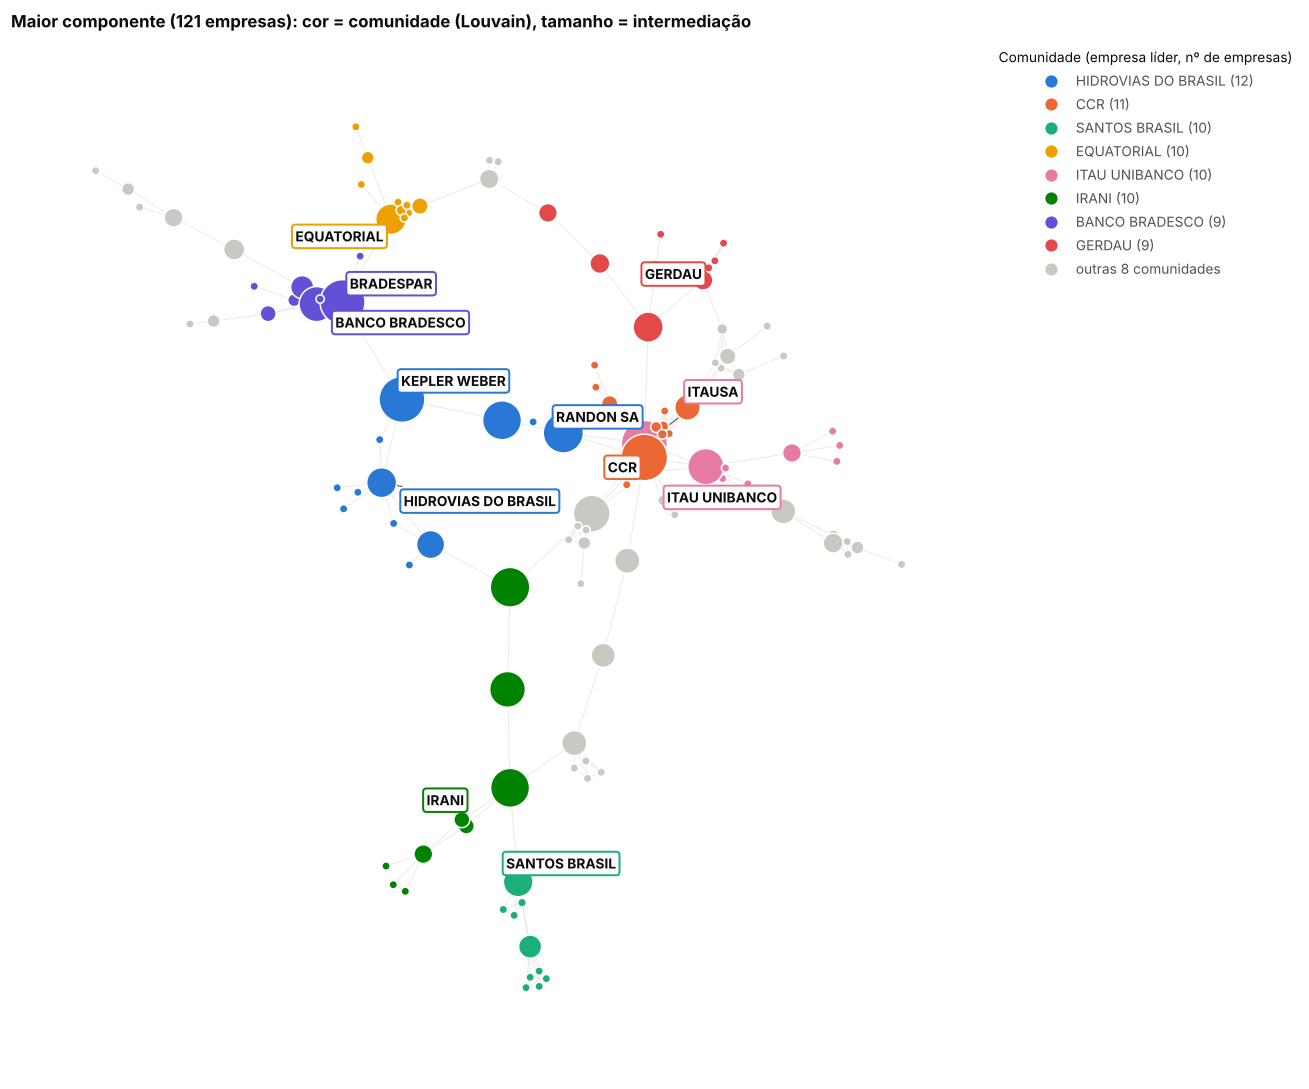

In [13]:
import re
from adjustText import adjust_text   # pip install adjustText
from matplotlib.lines import Line2D

def curto(n):
    n = re.sub(r'\s*-\s*EM RECUPERACAO.*$', '', nome[n])
    n = re.sub(r'\b(S\.?/?A\.?|SA|S/A\.?)\s*$', '', n).strip(' .-')
    n = re.sub(r'\b(E PARTICIPACOES|PARTICIPACOES|HOLDING|IMPLEMENTOS|SANEAMENTO|PAPEL E EMBALAGEM|OLEO E GAS)\b', '', n)
    n = re.sub(r'^(COMPANHIA|CIA)\s+', '', n)
    return ' '.join(n.split())[:20]

# As 8 maiores comunidades ganham cor; o resto fica cinza ("outras")
lider = {i: max(c, key=lambda n: (cent.pagerank[n], n)) for i, c in enumerate(comms)}
cor = lambda n: CAT[comm_de[n]] if comm_de[n] < 8 else OUTRAS

kk = nx.kamada_kawai_layout(L, weight=None)
pos = nx.spring_layout(L, pos=kk, k=0.22, iterations=60, seed=SEED)
bet = cent.intermediacao.loc[list(L)]
fig, ax = plt.subplots(figsize=(12, 10))
nx.draw_networkx_edges(L, pos, alpha=0.35, width=0.6, edge_color=AXIS, ax=ax)
nx.draw_networkx_nodes(L, pos, ax=ax, node_color=[cor(n) for n in L],
                       node_size=[30 + 900 * bet[n] / bet.max() for n in L], linewidths=1, edgecolors='white')

# Rótulos: a empresa líder de cada comunidade colorida + as 5 maiores pontes
rotular = list(dict.fromkeys([lider[i] for i in range(8)] + list(bet.sort_values(ascending=False).head(5).index)))
textos = [ax.text(pos[n][0], pos[n][1], curto(n), fontsize=9, fontweight='bold', ha='center', va='center', color=INK,
                  bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=cor(n), lw=1.3)) for n in rotular]
adjust_text(textos, x=[pos[n][0] for n in L], y=[pos[n][1] for n in L], ax=ax,
            expand=(1.4, 1.8), arrowprops=dict(arrowstyle='-', color=INK2, lw=0.7))

leg = [Line2D([0], [0], marker='o', ls='', ms=9, mfc=CAT[i], mec='white', label=f'{curto(lider[i])} ({len(comms[i])})')
       for i in range(8)]
leg.append(Line2D([0], [0], marker='o', ls='', ms=9, mfc=OUTRAS, mec='white', label=f'outras {len(comms) - 8} comunidades'))
ax.legend(handles=leg, title='Comunidade (empresa líder, nº de empresas)', loc='upper left', bbox_to_anchor=(1.0, 1.0),
          frameon=False, fontsize=9, title_fontsize=9, labelcolor=INK2)
ax.set_title(f'Maior componente ({L.number_of_nodes()} empresas): cor = comunidade (Louvain), tamanho = intermediação',
             fontsize=11, loc='left')
ax.axis('off'); plt.tight_layout(); plt.savefig('figuras/rede_comunidades.png', bbox_inches='tight'); plt.show()

## 7. Evolução temporal (aproximação)
O QSA é um **retrato de set/2024**: só aparecem os administradores atuais. Reconstruímos a rede de cada ano usando
apenas vínculos com `data_entrada <= ano`. **Viés de sobrevivência**: quem saiu da empresa antes de 2024 não aparece,
então anos antigos ficam sub-representados e as métricas tendem a crescer por construção. Por isso, além dos valores
absolutos, olhamos métricas relativas ao tamanho (fração de empresas interligadas, % no maior componente).

In [14]:
anos = range(2010, 2025)
evol = []
for ano in anos:
    s = soc[soc.data_entrada.dt.year <= ano]
    b = nx.Graph(); b.add_edges_from(zip(s.cnpj, s.pessoa))
    g = bipartite.weighted_projected_graph(b, set(s.cnpj))
    lcc = max(nx.connected_components(g), key=len)
    bt = nx.betweenness_centrality(g, normalized=True)
    evol.append({'ano': ano, '|V|': g.number_of_nodes(), '|E|': g.number_of_edges(),
                 'densidade': nx.density(g),
                 'grau médio': 2*g.number_of_edges()/g.number_of_nodes(),
                 'frac. empresas interligadas': 1 - nx.number_of_isolates(g)/g.number_of_nodes(),
                 'frac. no maior componente': len(lcc)/g.number_of_nodes(),
                 'intermediação média': np.mean(list(bt.values())),
                 'intermediação máxima': max(bt.values())})
evol = pd.DataFrame(evol).set_index('ano'); evol.to_csv('tabelas/evolucao_temporal.csv'); evol.round(6)

,|V|,|E|,densidade,grau médio,frac. empresas interligadas,frac. no maior componente,intermediação média,intermediação máxima
ano,,,,,,,,
2010,387,54,0.000723,0.279070,0.131783,0.018088,0.000000,0.000000
2011,412,57,0.000673,0.276699,0.126214,0.016990,0.000000,0.000000
2012,431,59,0.000637,0.273782,0.122970,0.016241,0.000000,0.000000
2013,463,60,0.000561,0.259179,0.118790,0.015119,0.000000,0.000000
2014,490,78,0.000651,0.318367,0.130612,0.014286,0.000000,0.000000
2015,539,83,0.000572,0.307978,0.131725,0.012987,0.000000,0.000000
2016,588,101,0.000585,0.343537,0.136054,0.013605,0.000000,0.000006
2017,638,126,0.000620,0.394984,0.161442,0.014107,0.000000,0.000010
2018,701,156,0.000636,0.445078,0.189729,0.012839,0.000000,0.000012


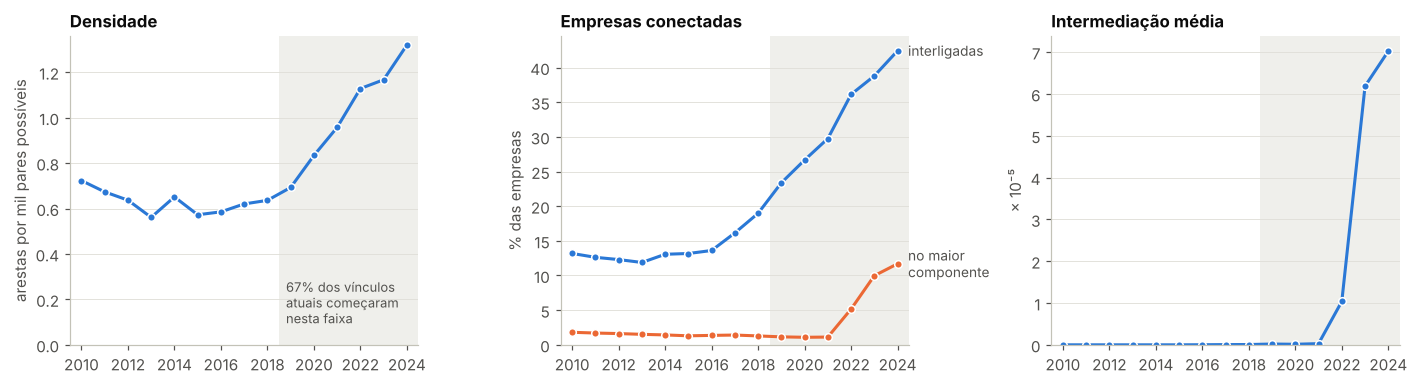

In [15]:
frac19 = (soc.data_entrada.dt.year >= 2019).mean()
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
ax[0].plot(evol.index, evol['densidade'] * 1000, lw=2, color=CAT[0], marker='o', ms=5, mec='white')
ax[0].set(title='Densidade', ylabel='arestas por mil pares possíveis')
ax[1].plot(evol.index, evol['frac. empresas interligadas'] * 100, lw=2, color=CAT[0], marker='o', ms=5, mec='white')
ax[1].plot(evol.index, evol['frac. no maior componente'] * 100, lw=2, color=CAT[1], marker='o', ms=5, mec='white')
ax[1].text(2024.45, evol['frac. empresas interligadas'].iloc[-1] * 100, 'interligadas', va='center', fontsize=9, color=INK2)
ax[1].text(2024.45, evol['frac. no maior componente'].iloc[-1] * 100, 'no maior\ncomponente', va='center', fontsize=9, color=INK2)
ax[1].set(title='Empresas conectadas', ylabel='% das empresas')
ax[2].plot(evol.index, evol['intermediação média'] * 1e5, lw=2, color=CAT[0], marker='o', ms=5, mec='white')
ax[2].set(title='Intermediação média', ylabel='× 10⁻⁵')
for a in ax:
    a.axvspan(2018.5, 2024.5, color=GRID, alpha=0.5, lw=0)
    a.set_xlim(2009.5, 2024.5 if a is not ax[1] else 2027.5); a.set_xticks(range(2010, 2025, 2)); a.set_ylim(bottom=0); a.grid(axis='x', visible=False)
ax[0].text(2018.8, ax[0].get_ylim()[1] * 0.06, f'{frac19:.0%} dos vínculos\natuais começaram\nnesta faixa', va='bottom', fontsize=8.5, color=INK2)
plt.tight_layout(); plt.savefig('figuras/evolucao_temporal.png', bbox_inches='tight'); plt.show()

## 8. Centralidade × capital social (variável externa)
O cadastro da Receita traz o **capital social** declarado de cada empresa. Testamos se as empresas mais centrais são também as de maior capital (correlação de Spearman, que não supõe relação linear). Empresas com capital social igual a zero foram tratadas como dado ausente.

In [16]:
from scipy.stats import spearmanr, mannwhitneyu
cent['capital'] = cent.index.map(emp.set_index('cnpj').capital_social)
d = cent[cent.capital > 0]
print(f'Empresas com capital social informado: {len(d)} de {len(cent)}')

metricas = ['grau', 'intermediacao', 'proximidade', 'pagerank', 'autovetor']
linhas = []
for nome_rede, base in [('rede inteira', d), ('maior componente', d[d.index.isin(lcc_nodes)])]:
    for m in metricas:
        if nome_rede == 'rede inteira' and m == 'autovetor':
            continue
        r, p = spearmanr(base[m], base.capital)
        linhas.append({'rede': nome_rede, 'métrica': m, 'n': len(base), 'rho': round(r, 3), 'p': p})
corr_cap = pd.DataFrame(linhas); corr_cap.to_csv('tabelas/correlacao_capital_social.csv', index=False)

iso, con = d[d.grau == 0].capital, d[d.grau > 0].capital
u = mannwhitneyu(con, iso, alternative='greater')
print(f'Mediana do capital social: interligadas R$ {con.median()/1e6:,.0f} mi | isoladas R$ {iso.median()/1e6:,.0f} mi '
      f'(Mann-Whitney unilateral, p = {u.pvalue:.1e})')
corr_cap

Empresas com capital social informado: 819 de 1035
Mediana do capital social: interligadas R$ 720 mi | isoladas R$ 73 mi (Mann-Whitney unilateral, p = 3.1e-17)


,rede,métrica,n,rho,p
0,rede inteira,grau,819,0.267,8.508224e-15
1,rede inteira,intermediacao,819,0.245,1.193274e-12
2,rede inteira,proximidade,819,0.317,1.332495e-20
3,rede inteira,pagerank,819,0.277,6.460392e-16
4,maior componente,grau,117,0.019,8.365615e-01
5,maior componente,intermediacao,117,0.339,1.836625e-04
6,maior componente,proximidade,117,0.264,3.986740e-03
7,maior componente,pagerank,117,0.098,2.954366e-01
8,maior componente,autovetor,117,0.247,7.277840e-03


/tmp/ipykernel_248/1726432217.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(grupos, vert=False, widths=0.5, patch_artist=True, showfliers=False, whis=(5, 95),


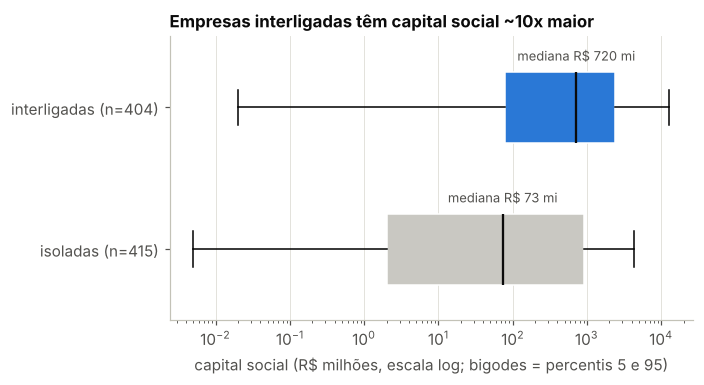

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
grupos = [iso / 1e6, con / 1e6]
bp = ax.boxplot(grupos, vert=False, widths=0.5, patch_artist=True, showfliers=False, whis=(5, 95),
                medianprops=dict(color=INK, lw=1.5))
for b, c in zip(bp['boxes'], [OUTRAS, CAT[0]]):
    b.set(facecolor=c, edgecolor='white')
ax.set_xscale('log')
ax.set_yticks([1, 2], [f'isoladas (n={len(iso)})', f'interligadas (n={len(con)})'])
ax.set(xlabel='capital social (R$ milhões, escala log; bigodes = percentis 5 e 95)',
       title='Empresas interligadas têm capital social ~10x maior')
ax.grid(axis='y', visible=False)
for i, g in enumerate(grupos, start=1):
    ax.text(g.median(), i + 0.33, f'mediana R$ {g.median():,.0f} mi'.replace(',', '.'), ha='center', fontsize=8.5, color=INK2)
plt.tight_layout(); plt.savefig('figuras/capital_social.png', bbox_inches='tight'); plt.show()

## 9. Exporta o grafo (GraphML e GEXF, para Gephi)

In [18]:
for n in G:
    G.nodes[n].update({k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else str(v))
                       for k, v in cent.loc[n].items() if pd.notna(v)})
for u, v, d in G.edges(data=True): d.pop('dist', None)
nx.write_gexf(G, 'rede_sa_abertas.gexf'); nx.write_graphml(G, 'rede_sa_abertas.graphml'); cent.to_csv('tabelas/centralidades_todas.csv')